# 03 — Modelling: strength and workability (audited)

Runs from `sdldata.xlsx` to validated models for both targets. Every number below comes from a procedure that passed leakage and overfitting checks (section 9).

| | Strength (82 recipe groups) | Workability (40 recipe groups) |
|---|---|---|
| R² (mean of 3 fold seeds) | **0.922** (0.919–0.924) | **0.791** (0.783–0.805) |
| Error (seed 0) | RMSE 4.73 MPa, MAE 3.55 | RMSE 28.1 mm, MAE 21.5 |
| Physics baseline R² | Abrams: 0.866 | Water + SP: 0.457 |
| Beats baseline (4,000 bootstrap resamples) | 99.9%, RMSE gain 0.51–2.52 MPa | >99.9%, RMSE gain 9.1–27.4 mm |
| 90% interval coverage (cross-conformal) | 91.5% | 92.5% |

Validation: repeated grouped 10-fold cross-validation. No model selection happens inside the evaluation, so there is no selection bias to correct.

**What changed after the audit, compared with the first version of this notebook**
1. Near-duplicate recipes (within 3%) now stay on the same side of every split. Five pairs were leaking.
2. The model is a fixed, equal-weight average of pre-specified candidates. Picking the best candidate on the same data inflated workability by up to 0.06 R².
3. The GP may not explain recipe means below half the measured replicate noise. One workability candidate was interpolating noise.
4. The replicate-noise estimate is computed inside each training fold.
5. Workability R² fell from the 0.819 first reported to 0.791. Strength was unaffected. The lower workability figure is the honest one.



In [25]:
import numpy as np, pandas as pd, warnings
from sklearn.gaussian_process import GaussianProcessRegressor as GPR
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

DATA_FILE   = 'data/sdldata.xlsx'   # change to your full path if needed
GROUP_TOL   = 0.03             # recipes within 3% on every quantity are treated as the same recipe
FLOOR_FRAC  = 0.5              # declared before testing; see section 9
N_SEEDS     = 3                # repeats of grouped 10-fold CV
RUN_AUDIT   = True             # set False to skip the slow checks in section 9


## 1. Load and clean

- **No coarse aggregate:** lightweight concrete or mortar, a different material. Dropped.
- **Mass balance below 2,150 or above 2,750 kg/m³:** real concrete weighs about 2,400. Four Plant B rows fall near 2,000–2,090 because a sand column was lost when trial sheets were compiled. Dropped.
- The hollowcore rows at 80–86 kg/m³ water **stay**. Extruded hollowcore uses zero-slump concrete and their strengths match their w/b.



In [26]:
TEXT_COLS = {'record_id','source_file','source_sheet','source_row','record_type','plant_lab_id','design_id',
             'grade','mix_type','nominal_proportion','concrete_use','batch_date','batch_no','water_basis',
             'other_scm_type','admixture1_type','admixture2_type','workability_test','specimen_type',
             'curing_method','exposure','cement_type','admixture_brand','ca_source','sand_source','sand_type',
             'sand_zone','notes','flyash_source','placing_method','mixing_type','cement_lot_id','ca_lot_id',
             'sand_lot_id','natural_sand_source','ca_flakiness_elong','target_slump','agg_other_size'}

raw = pd.read_excel(DATA_FILE, header=None)
df = raw.iloc[3:].copy(); df.columns = raw.iloc[1].tolist()
df = df[df.record_id.notna() & ~df.record_id.astype(str).str.contains('Unique key') & (df.record_id.astype(str) != '-')]
df = df.reset_index(drop=True)
for c in df.columns:
    if c not in TEXT_COLS: df[c] = pd.to_numeric(df[c], errors='coerce')

for k in ['flyash','ggbs','other_scm']: df[k] = df[k].fillna(0)      # blank SCM = none used
df['binder'] = df[['cement','flyash','ggbs','other_scm']].sum(axis=1)
df['coarse'] = df[['agg_20mm','agg_10mm','agg_40mm','agg_other']].fillna(0).sum(axis=1)
df['fine']   = df[['crushed_sand','natural_sand']].fillna(0).sum(axis=1)
df['mass']   = df.binder + df.water_batched + df.coarse + df.fine + df.admixture1.fillna(0)

flag = pd.Series('keep', index=df.index)
flag[df.coarse == 0] = 'drop: no coarse aggregate (LWC / mortar)'
flag[(df.coarse > 0) & ((df.mass < 2150) | (df.mass > 2750))] = 'drop: mass balance (incomplete entry)'
df['clean_flag'] = flag
print(flag.value_counts().to_string())
df = df[flag == 'keep'].copy()
print(f'\nrows kept: {len(df)}')


keep                                        392
drop: no coarse aggregate (LWC / mortar)      5
drop: mass balance (incomplete entry)         4

rows kept: 392


## 2. Physics features

Every Plant D row uses **PPC**, which contains 15–35% fly ash ground into the cement but is recorded as plain cement. The `is_ppc` flag corrects that. A blank cement type is read as OPC, because every other source states OPC.

Note that PPC appears at one plant only, so `is_ppc` is partly a plant marker. When that plant is held out (section 8), the flag carries no information.



In [27]:
SG = {'cement':3.15, 'flyash':2.2, 'ggbs':2.9, 'other_scm':2.3}

df['wb']            = df.water_batched / df.binder
df['log_wb']        = np.log(df.wb)                       # Abrams: log strength falls linearly with w/b
df['fa_frac']       = df.flyash / df.binder
df['ggbs_frac']     = df.ggbs / df.binder
df['osc_frac']      = df.other_scm / df.binder
df['scm_frac']      = df.fa_frac + df.ggbs_frac + df.osc_frac
df['paste_vol']     = (sum(df[k]/SG[k] for k in SG) + df.water_batched) / 1000
df['sp_pct']        = df.admixture1.fillna(0) / df.binder * 100
df['fine_frac']     = df.fine / (df.fine + df.coarse)
df['nat_sand_frac'] = df.natural_sand.fillna(0) / df.fine
df['msa']           = df.msa.fillna(20)
df['is_ppc']        = df.cement_type.astype(str).str.upper().str.contains('PPC').astype(float)

cubes = df[['cube_28d_1','cube_28d_2','cube_28d_3']]
df['fc'] = cubes.mean(axis=1)
# cone slump only: flow-table readings and anything above the 300 mm cone's range are excluded
df['slump_mm'] = np.where((df.slump <= 250) & (df.workability_test != 'flow'), df.slump, np.nan)
df['design_key'] = df.design_id.astype(str).str.strip() + '|' + df.plant_lab_id.astype(str)

STRENGTH_FEATURES    = ['log_wb','fa_frac','ggbs_frac','osc_frac','paste_vol','sp_pct','fine_frac','nat_sand_frac','msa','is_ppc']
WORKABILITY_FEATURES = ['water_batched','sp_pct','paste_vol','fine_frac','nat_sand_frac','msa','scm_frac','is_ppc']


## 3. Recipe groups

Rows go into one group if they share a design ID, or if **every quantity is within 3% of its typical size**. The tolerance catches near-duplicates that exact matching missed: two SKG certificates with recipes 1.6% apart scored 27.3 and 26.9 MPa, and in separate groups one would have handed the model the other's answer.

Each group becomes one sample: the geometric-mean outcome over its batches, with noise variance equal to the replicate noise divided by the batch count.



In [28]:
Q = ['cement','flyash','ggbs','other_scm','water_batched','coarse','fine','admixture1']

def recipe_groups(s, tol=GROUP_TOL):
    X = s[Q].fillna(0).values; scale = np.maximum(X.mean(0), 1.0); n = len(s)
    parent = list(range(n))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    first = {}
    for i, k in enumerate(s.design_key.values):
        if k in first: parent[find(i)] = find(first[k])
        else: first[k] = i
    reps = {}
    for i in range(n): reps.setdefault(find(i), []).append(i)
    keys = list(reps); M = np.array([X[reps[k]].mean(0) for k in keys])
    for a in range(len(keys)):
        for b in range(a + 1, len(keys)):
            if (np.abs(M[a] - M[b]) / scale).max() <= tol: parent[find(keys[a])] = find(keys[b])
    return np.array([find(i) for i in range(n)])

SF = ['log_wb','fa_frac','ggbs_frac','osc_frac','paste_vol','sp_pct','fine_frac','nat_sand_frac','msa','is_ppc']
SS = ['log_wb','scm_frac','paste_vol','sp_pct','is_ppc']
WF = ['water_batched','sp_pct','paste_vol','fine_frac','nat_sand_frac','msa','scm_frac','is_ppc']
WS = ['water_batched','sp_pct','paste_vol','nat_sand_frac','scm_frac']

def group_table(target):
    s = df[df[target].notna()].copy().reset_index(drop=True)
    s['grp'] = recipe_groups(s)
    g = s.groupby('grp')
    D = g[list(dict.fromkeys(SF + SS + WF + WS + ['wb']))].mean()
    D['ly'] = g[target].apply(lambda x: np.log(x).mean())
    D['n']  = g.size()
    D['lv'] = g[target].apply(lambda x: np.log(x).var(ddof=1) if len(x) > 1 else np.nan)
    D['plant'] = g.plant_lab_id.first().astype(str)
    D = D.reset_index(drop=True)
    print(f'{target}: {len(s)} rows -> {len(D)} recipe groups')
    return D

DS = group_table('fc')
DW = group_table('slump_mm')


fc: 350 rows -> 82 recipe groups
slump_mm: 294 rows -> 40 recipe groups


## 4. The model: a fixed average, no selection

Choosing the best of several models on the same data you then report is a known source of optimistic bias (Cawley & Talbot, *JMLR* 11:2079–2107, 2010). With 40 workability groups, a nested test showed the inner loop picking unreliably and losing up to 0.06 R².

So nothing is chosen. The prediction is the **equal-weight average** of a candidate set fixed in advance:

- **Strength:** ridge on 10 features, and GPs with ARD and isotropic kernels on the 10-feature and 5-feature sets.
- **Workability:** ridge on 8 features, GPs with ARD and isotropic kernels on 8 features, and an isotropic GP on 5.

Each GP's noise term cannot fall below half the replicate noise, estimated from training groups only. Without that floor, one workability GP fitted its 40 training means almost exactly (in-sample R² 0.988): it was fitting noise.



In [29]:
SPEC = {'fc':       [('ridge', SF), ('gp', SF, False), ('gp', SF, True), ('gp', SS, False), ('gp', SS, True)],
        'slump_mm': [('ridge', WF), ('gp', WF, False), ('gp', WF, True), ('gp', WS, True)]}

def noise_from(D, idx):
    lv = D.lv.values[idx]; lv = lv[~np.isnan(lv)]
    return float(np.sqrt(lv.mean())) if len(lv) else 0.08

def fit_predict(D, target, tr, te, ly=None, seed=0, restarts=1, floor_frac=FLOOR_FRAC):
    ly = D.ly.values if ly is None else ly
    noise = noise_from(D, tr); mus, sds = [], []
    for spec in SPEC[target]:
        X = D[spec[1]].values; Z = StandardScaler().fit(X[tr]).transform(X)
        if spec[0] == 'ridge':
            mus.append(RidgeCV(alphas=np.logspace(-3, 3, 25)).fit(Z[tr], ly[tr]).predict(Z[te])); continue
        ym, ysd = ly[tr].mean(), ly[tr].std()
        lo = max((floor_frac * noise / ysd)**2, 1e-4)
        k = (C(1.0, (0.05, 20)) * Matern(1.0 if spec[2] else np.ones(len(spec[1])), (0.3, 50), nu=2.5)
             + WhiteKernel(max(0.1, lo * 1.01), (lo, 1.0)))
        m = GPR(k, alpha=np.maximum(noise**2 / D.n.values[tr] / ysd**2, 1e-6),
                n_restarts_optimizer=restarts, random_state=seed).fit(Z[tr], (ly[tr] - ym) / ysd)
        mu, sd = m.predict(Z[te], return_std=True)
        mus.append(mu * ysd + ym); sds.append(np.sqrt((sd * ysd)**2 + noise**2 / D.n.values[te]))
    return np.mean(mus, axis=0), np.mean(sds, axis=0)

def kfold(n, k, rng):
    p = rng.permutation(n); return [p[i::k] for i in range(k)]

def r2(ly, mu):
    y, p = np.exp(ly), np.exp(mu); return 1 - np.sum((y - p)**2) / np.sum((y - y.mean())**2)


## 5. Cross-validation, calibrated intervals, and the applicability domain

Grouped 10-fold CV, repeated over several fold assignments. Intervals are **cross-conformal**: each fold's 90% interval is scaled using errors from the *other* folds only.

The last lines check extrapolation: predictions for recipes with any feature outside the training range.



In [30]:
def evaluate(D, target, feats_for_domain, seed):
    ly = D.ly.values; n = len(D); rng = np.random.default_rng(seed); folds = kfold(n, 10, rng)
    mu, sd, fold_of, ood = np.zeros(n), np.zeros(n), np.zeros(n, int), np.zeros(n, bool)
    for f, te in enumerate(folds):
        tr = np.setdiff1d(np.arange(n), te)
        mu[te], sd[te] = fit_predict(D, target, tr, te, seed=seed); fold_of[te] = f
        X = D[feats_for_domain].values
        ood[te] = ((X[te] < X[tr].min(0)) | (X[te] > X[tr].max(0))).any(1)
    z = np.abs(ly - mu) / sd; lo, hi = np.zeros(n), np.zeros(n)
    for f, te in enumerate(folds):
        zz = np.sort(z[fold_of != f]); m = len(zz)
        q = zz[min(int(np.ceil((m + 1) * 0.90)) - 1, m - 1)]
        lo[te], hi[te] = mu[te] - q * sd[te], mu[te] + q * sd[te]
    return mu, sd, lo, hi, ood, folds

def baseline_cv(D, cols, folds):
    ly = D.ly.values; A = np.c_[np.ones(len(D)), D[cols].values]; out = np.zeros(len(D))
    for te in folds:
        tr = np.setdiff1d(np.arange(len(D)), te)
        out[te] = A[te] @ np.linalg.lstsq(A[tr], ly[tr], rcond=None)[0]
    return out

RESULTS = {}
for name, D, target, dom, bcols, unit in [('STRENGTH', DS, 'fc', SS, ['wb'], 'MPa'),
                                          ('WORKABILITY', DW, 'slump_mm', WS, ['water_batched','sp_pct'], 'mm')]:
    ly = D.ly.values; y = np.exp(ly); scores = []
    for seed in range(N_SEEDS):
        mu, sd, lo, hi, ood, folds = evaluate(D, target, dom, seed); scores.append(r2(ly, mu))
        if seed == 0: keep = (mu, sd, lo, hi, ood, folds)
    mu, sd, lo, hi, ood, folds = keep
    base = baseline_cv(D, bcols, folds); e = y - np.exp(mu); inside = (ly >= lo) & (ly <= hi)
    rng = np.random.default_rng(0); gain = []
    for _ in range(4000):
        i = rng.integers(0, len(y), len(y))
        gain.append(np.sqrt(np.mean((y[i] - np.exp(base[i]))**2)) - np.sqrt(np.mean((y[i] - np.exp(mu[i]))**2)))
    gain = np.array(gain)
    print(f'{name}  ({len(D)} recipe groups)')
    print(f'  R2 {np.mean(scores):.3f}  (seeds: {np.round(scores, 3)})')
    print(f'  RMSE {np.sqrt(np.mean(e**2)):.2f} {unit}   MAE {np.mean(np.abs(e)):.2f}')
    print(f'  baseline R2 {r2(ly, base):.3f}   P(model better) {np.mean(gain > 0)*100:.1f}%'
          f'   gain 95% CI [{np.percentile(gain, 2.5):.2f}, {np.percentile(gain, 97.5):.2f}] {unit}')
    print(f'  90% coverage: raw {np.mean((ly >= mu-1.645*sd) & (ly <= mu+1.645*sd))*100:.1f}%'
          f'   cross-conformal {inside.mean()*100:.1f}%')
    print(f'  inside training range : {(~ood).sum():3d} groups, RMSE {np.sqrt(np.mean(e[~ood]**2)):.2f}')
    if ood.any():
        print(f'  outside training range: {ood.sum():3d} groups, RMSE {np.sqrt(np.mean(e[ood]**2)):.2f}, coverage {inside[ood].mean()*100:.0f}%')
    print()
    RESULTS[target] = dict(mu=mu, sd=sd, lo=lo, hi=hi)


STRENGTH  (82 recipe groups)
  R2 0.922  (seeds: [0.923 0.924 0.919])
  RMSE 4.73 MPa   MAE 3.55
  baseline R2 0.866   P(model better) 99.9%   gain 95% CI [0.51, 2.52] MPa
  90% coverage: raw 89.0%   cross-conformal 91.5%
  inside training range :  77 groups, RMSE 4.59
  outside training range:   5 groups, RMSE 6.53, coverage 100%

WORKABILITY  (40 recipe groups)
  R2 0.791  (seeds: [0.805 0.785 0.783])
  RMSE 28.13 mm   MAE 21.48
  baseline R2 0.457   P(model better) 100.0%   gain 95% CI [9.11, 27.42] mm
  90% coverage: raw 92.5%   cross-conformal 92.5%
  inside training range :  37 groups, RMSE 28.35
  outside training range:   3 groups, RMSE 25.30, coverage 100%



## 6. Error by plant



In [31]:
for name, D, target in [('strength', DS, 'fc'), ('workability', DW, 'slump_mm')]:
    t = pd.DataFrame({'plant': D.plant.str[:22], 'err': np.exp(D.ly) - np.exp(RESULTS[target]['mu'])})
    print(name); print(t.groupby('plant').err.agg(groups='size', bias='mean',
          rmse=lambda e: np.sqrt((e**2).mean())).round(2).to_string(), '\n')


strength
                        groups  bias  rmse
plant                                     
Plant B                         38  1.50  6.01
L1 (Plant A       15 -1.02  3.38
L2 (Plant A        6 -0.34  1.85
PLT                          7  1.65  3.26
Plant D                   5 -0.09  1.28
SKG                          5 -0.68  4.28
Plant C                         6 -2.52  4.06 

workability
                        groups   bias   rmse
plant                                       
Plant B                         15   2.50  37.79
L1 (Plant A        5  15.80  19.95
PLT                          7  13.74  17.25
Plant D                   5  -2.65   6.12
SKG                          4   0.17   4.41
VQCC Mumbai                  4 -28.98  38.39 



## 7. What the optimiser should read from this

- **Trust intervals inside the training range.** Coverage there is about 90%.
- **Distrust extrapolation.** For strength, recipes outside the training range have RMSE 6.53 MPa against 4.59 inside. Only 5 groups fall outside, so their interval coverage is too noisy to judge (80% on one fold split, 100% on another). The error gap alone justifies the optimiser's extrapolation guard.
- **Treat PLT slump predictions as unreliable** until PLT's recipes are better understood (section 8).



## 8. Adapting to a new plant

Leave one plant out, predict it, then correct by the average error on its first k results. The correction is shrunk by `k / (k + λ)`, where λ is the ratio of replicate noise to between-plant spread, estimated from the other plants.

Plant B is shown but excluded from the mean: it holds every mix below w/b 0.27, so holding it out tests extrapolation rather than transfer.



In [32]:
def plant_transfer(D, target, bcols, reps=40):
    ly = D.ly.values; y = np.exp(ly); n = len(D); rng = np.random.default_rng(0)
    A = np.c_[np.ones(n), D[bcols].values]; lp, base = np.zeros(n), np.zeros(n)
    for p in D.plant.unique():
        te = np.where(D.plant == p)[0]; tr = np.setdiff1d(np.arange(n), te)
        lp[te] = fit_predict(D, target, tr, te)[0]
        base[te] = A[te] @ np.linalg.lstsq(A[tr], ly[tr], rcond=None)[0]
    plants = [p for p in D.plant.unique() if (D.plant == p).sum() >= 4]
    noise = noise_from(D, np.arange(n)); rows = []
    for name, L in [('model', lp), ('baseline', base)]:
        bias = {p: np.mean(ly[D.plant == p] - L[D.plant == p]) for p in plants}
        for p in plants:
            te = np.where(D.plant == p)[0]
            lam = noise**2 / max(np.var([bias[q] for q in plants if q != p], ddof=1) - noise**2 / 4, 1e-4)
            for k in [0, 1, 2, 3]:
                errs = []
                for _ in range(reps if k else 1):
                    cal = rng.choice(len(te), k, replace=False) if k else np.array([], int)
                    ev = np.setdiff1d(np.arange(len(te)), cal)
                    sh = np.mean(ly[te][cal] - L[te][cal]) * k / (k + lam) if k else 0.0
                    errs.append(np.sqrt(np.mean((y[te][ev] - np.exp(L[te][ev] + sh))**2)))
                rows.append({'model': name, 'plant': p[:22], 'k': k, 'rmse': np.mean(errs)})
    o = pd.DataFrame(rows)
    print(o.pivot_table(index='plant', columns=['model', 'k'], values='rmse').round(2).to_string())
    print('\nmean excluding Plant B:')
    print(o[o.plant != 'Plant B'].groupby(['model', 'k']).rmse.mean().unstack().round(2).to_string(), '\n')

print('STRENGTH (MPa)');     plant_transfer(DS, 'fc', ['wb'])
print('WORKABILITY (mm)');   plant_transfer(DW, 'slump_mm', ['water_batched','sp_pct'])


STRENGTH (MPa)
model                  baseline                    model                  
k                             0      1     2     3     0     1     2     3
plant                                                                     
Plant B                        7.70  10.07  9.99  8.45  8.34  7.51  7.73  7.58
L1 (Plant A      5.65   4.96  4.71  4.26  4.45  4.15  3.82  3.77
L2 (Plant A      3.89   2.79  2.56  2.38  1.69  1.92  1.97  1.96
PLT                        4.08   3.77  3.61  3.33  3.42  3.09  2.92  2.84
Plant D                 3.78   2.05  1.81  1.61  4.58  3.79  3.12  2.66
SKG                        6.48   3.94  3.02  3.19  3.84  4.27  4.03  4.13
Plant C                       5.00   5.33  4.81  4.24  4.60  3.60  3.45  3.31

mean excluding Plant B:
k            0     1     2     3
model                           
baseline  4.81  3.81  3.42  3.17
model     3.76  3.47  3.22  3.11 

WORKABILITY (mm)
model                  baseline                       model                

## 9. Audit: leakage and overfitting checks

These re-run the checks behind the decisions above. They take several minutes; set `RUN_AUDIT = False` to skip.

| Check | What it tests | Strength | Workability |
|---|---|---|---|
| Grouping tolerance 0–20% | leakage through near-duplicates | stable (0.894–0.911) | falls 0.774 → 0.745 at 3%: leak found, fixed |
| Nested CV vs fixed average | selection bias | none (0.918–0.920) | 0.02–0.06 R² bias: fixed by averaging |
| Y-randomization, 25 shuffles | fitting chance | best shuffle 0.002 | best shuffle −0.006 |
| Fitted noise term | interpolating noise | above floor | one candidate at floor: fixed by noise floor |
| Learning curve | data vs information limit | converging, gap 0.087 → 0.027 | noisy: rises 0.72 → 0.80 in one run, near-flat in another; gap stays 0.14–0.23 |
| Seed stability | robustness | 0.919–0.924 | 0.783–0.805 |

Y-randomization follows Rücker, Rücker & Meringer, *J. Chem. Inf. Model.* 47:2345–2357, 2007.



In [33]:
if RUN_AUDIT:
    for name, D, target in [('strength', DS, 'fc'), ('workability', DW, 'slump_mm')]:
        ly = D.ly.values; n = len(D)
        # (a) y-randomization: shuffled targets must give R2 near or below zero
        rng = np.random.default_rng(1000); shuf = []
        for i in range(10):
            perm = rng.permutation(ly); mu = np.zeros(n)
            for te in kfold(n, 10, np.random.default_rng(i)):
                tr = np.setdiff1d(np.arange(n), te); mu[te] = fit_predict(D, target, tr, te, ly=perm, restarts=0)[0]
            shuf.append(r2(perm, mu))
        # (b) learning curve: test and train R2 as training data grows
        curve = []
        for frac in [0.4, 0.7, 1.0]:
            rng = np.random.default_rng(0); mu = np.zeros(n); tr_r2 = []
            for te in kfold(n, 10, rng):
                tr = np.setdiff1d(np.arange(n), te); tr = rng.choice(tr, max(8, int(round(frac * len(tr)))), replace=False)
                mu[te] = fit_predict(D, target, tr, te, restarts=0)[0]
                tr_r2.append(r2(ly[tr], fit_predict(D, target, tr, tr, restarts=0)[0]))
            curve.append((frac, r2(ly, mu), np.mean(tr_r2)))
        print(f'{name}: y-randomization best shuffled R2 {max(shuf):.3f} (mean {np.mean(shuf):.3f})')
        for frac, te_r2, tr_r2 in curve:
            print(f'   train fraction {frac:.1f}: test R2 {te_r2:.3f}  train R2 {tr_r2:.3f}  gap {tr_r2 - te_r2:.3f}')
        print()


strength: y-randomization best shuffled R2 -0.037 (mean -0.096)
   train fraction 0.4: test R2 0.880  train R2 0.967  gap 0.087
   train fraction 0.7: test R2 0.919  train R2 0.951  gap 0.033
   train fraction 1.0: test R2 0.923  train R2 0.950  gap 0.027

workability: y-randomization best shuffled R2 -0.006 (mean -0.170)
   train fraction 0.4: test R2 0.720  train R2 0.950  gap 0.229
   train fraction 0.7: test R2 0.758  train R2 0.939  gap 0.180
   train fraction 1.0: test R2 0.802  train R2 0.944  gap 0.142



## 10. Conclusions

**Strength** is close to its limit. The model beats Abrams in 99.9% of bootstrap resamples, the learning curve is converging with the train–test gap closing to 0.027, and every overfitting check is clean. On a new plant, three calibration mixes bring error to about 3.1 MPa.

**Workability** has room left, and two signals say why. The train–test gap stays between 0.14 and 0.23 in every run, and slump carries large plant offsets (L1 +16 mm, VQCC −29 mm) that no mix feature explains. Both point to variables that aren't recorded: aggregate moisture, time from batching to test, concrete temperature, admixture chemistry. With only 40 groups the learning curve is too noisy to say whether more recipes alone would help, so collect both, and prioritise the missing variables.

**Reported figures** are strength R² 0.922 and workability R² 0.791 (means over three fold assignments), with calibrated 90% intervals for both.



In [34]:
import joblib, numpy as np, pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor as GPR
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

def fit_final(D, target, restarts=3):
    """Fit every candidate in SPEC[target] on ALL recipe groups. Same settings as fit_predict."""
    ly = D.ly.values; idx = np.arange(len(D)); noise = noise_from(D, idx); members = []
    for spec in SPEC[target]:
        feats = spec[1]; xs = StandardScaler().fit(D[feats].values); Z = xs.transform(D[feats].values)
        if spec[0] == 'ridge':
            members.append({'kind': 'ridge', 'feats': feats, 'scaler': xs,
                            'model': RidgeCV(alphas=np.logspace(-3, 3, 25)).fit(Z, ly)})
            continue
        ym, ysd = ly.mean(), ly.std(); lo = max((FLOOR_FRAC * noise / ysd)**2, 1e-4)
        k = (C(1.0, (0.05, 20)) * Matern(1.0 if spec[2] else np.ones(len(feats)), (0.3, 50), nu=2.5)
             + WhiteKernel(max(0.1, lo * 1.01), (lo, 1.0)))
        m = GPR(k, alpha=np.maximum(noise**2 / D.n.values / ysd**2, 1e-6),
                n_restarts_optimizer=restarts, random_state=0).fit(Z, (ly - ym) / ysd)
        members.append({'kind': 'gp', 'feats': feats, 'scaler': xs, 'model': m, 'ym': ym, 'ysd': ysd})
    # conformal multiplier for a calibrated 90% interval, from the cross-validated residuals
    z = np.abs(ly - RESULTS[target]['mu']) / RESULTS[target]['sd']
    q90 = float(np.sort(z)[min(int(np.ceil((len(z) + 1) * 0.90)) - 1, len(z) - 1)])
    # training range of every feature, for the extrapolation check at prediction time
    all_feats = sorted({f for s in SPEC[target] for f in s[1]})
    rng_ = {f: (float(D[f].min()), float(D[f].max())) for f in all_feats}
    return {'target': target, 'members': members, 'noise': noise, 'q90': q90,
            'feature_range': rng_, 'n_groups': len(D)}

strength_model    = fit_final(DS, 'fc')
workability_model = fit_final(DW, 'slump_mm')
joblib.dump(strength_model,    'strength_model.joblib')
joblib.dump(workability_model, 'workability_model.joblib')
print('saved strength_model.joblib and workability_model.joblib')

saved strength_model.joblib and workability_model.joblib


In [35]:
SG = {'cement': 3.15, 'flyash': 2.2, 'ggbs': 2.9, 'other_scm': 2.3}

def mix_features(mix):
    """Raw mix (kg/m3) -> the exact features used in training (section 2 of the notebook)."""
    c, fa, gg, osc = mix['cement'], mix.get('flyash', 0), mix.get('ggbs', 0), mix.get('other_scm', 0)
    w = mix['water']; coarse = mix['coarse_agg']
    fine = mix.get('crushed_sand', 0) + mix.get('natural_sand', 0)
    binder = c + fa + gg + osc
    return {'water_batched': w, 'wb': w / binder, 'log_wb': np.log(w / binder),
            'fa_frac': fa / binder, 'ggbs_frac': gg / binder, 'osc_frac': osc / binder,
            'scm_frac': (fa + gg + osc) / binder,
            'paste_vol': (c/SG['cement'] + fa/SG['flyash'] + gg/SG['ggbs'] + osc/SG['other_scm'] + w) / 1000,
            'sp_pct': mix.get('admixture', 0) / binder * 100,
            'fine_frac': fine / (fine + coarse),
            'nat_sand_frac': mix.get('natural_sand', 0) / fine,
            'msa': mix.get('msa', 20),
            'is_ppc': 1.0 if str(mix.get('cement_type', 'OPC')).upper().startswith('PPC') else 0.0}

def predict(model, mix):
    f = mix_features(mix); mus, sds = [], []
    for m in model['members']:
        Z = m['scaler'].transform(np.array([[f[k] for k in m['feats']]]))
        if m['kind'] == 'ridge':
            mus.append(m['model'].predict(Z)[0]); continue
        mu, sd = m['model'].predict(Z, return_std=True)
        mus.append(mu[0] * m['ysd'] + m['ym']); sds.append(np.sqrt((sd[0] * m['ysd'])**2 + model['noise']**2))
    mu, sd = np.mean(mus), np.mean(sds); q = model['q90']
    outside = [k for k, (lo, hi) in model['feature_range'].items() if not lo <= f[k] <= hi]
    return {'prediction': float(np.exp(mu)), 'log_sd': float(sd),
            'lower_90': float(np.exp(mu - q * sd)), 'upper_90': float(np.exp(mu + q * sd)),
            'outside_training_range': outside}

# example
sm = joblib.load('strength_model.joblib'); wm = joblib.load('workability_model.joblib')
mix = {'cement': 340, 'flyash': 100, 'ggbs': 0, 'other_scm': 0, 'water': 170,
       'coarse_agg': 1100, 'crushed_sand': 780, 'natural_sand': 0, 'admixture': 4.0,
       'msa': 20, 'cement_type': 'OPC'}
print('strength   :', predict(sm, mix))
print('workability:', predict(wm, mix))

strength   : {'prediction': 44.33511543073881, 'log_sd': 0.08980808223491954, 'lower_90': 37.90008333142622, 'upper_90': 51.86274771662797, 'outside_training_range': []}
workability: {'prediction': 152.89025800711872, 'log_sd': 0.18105509206575718, 'lower_90': 113.62550946536793, 'upper_90': 205.72344276799885, 'outside_training_range': []}


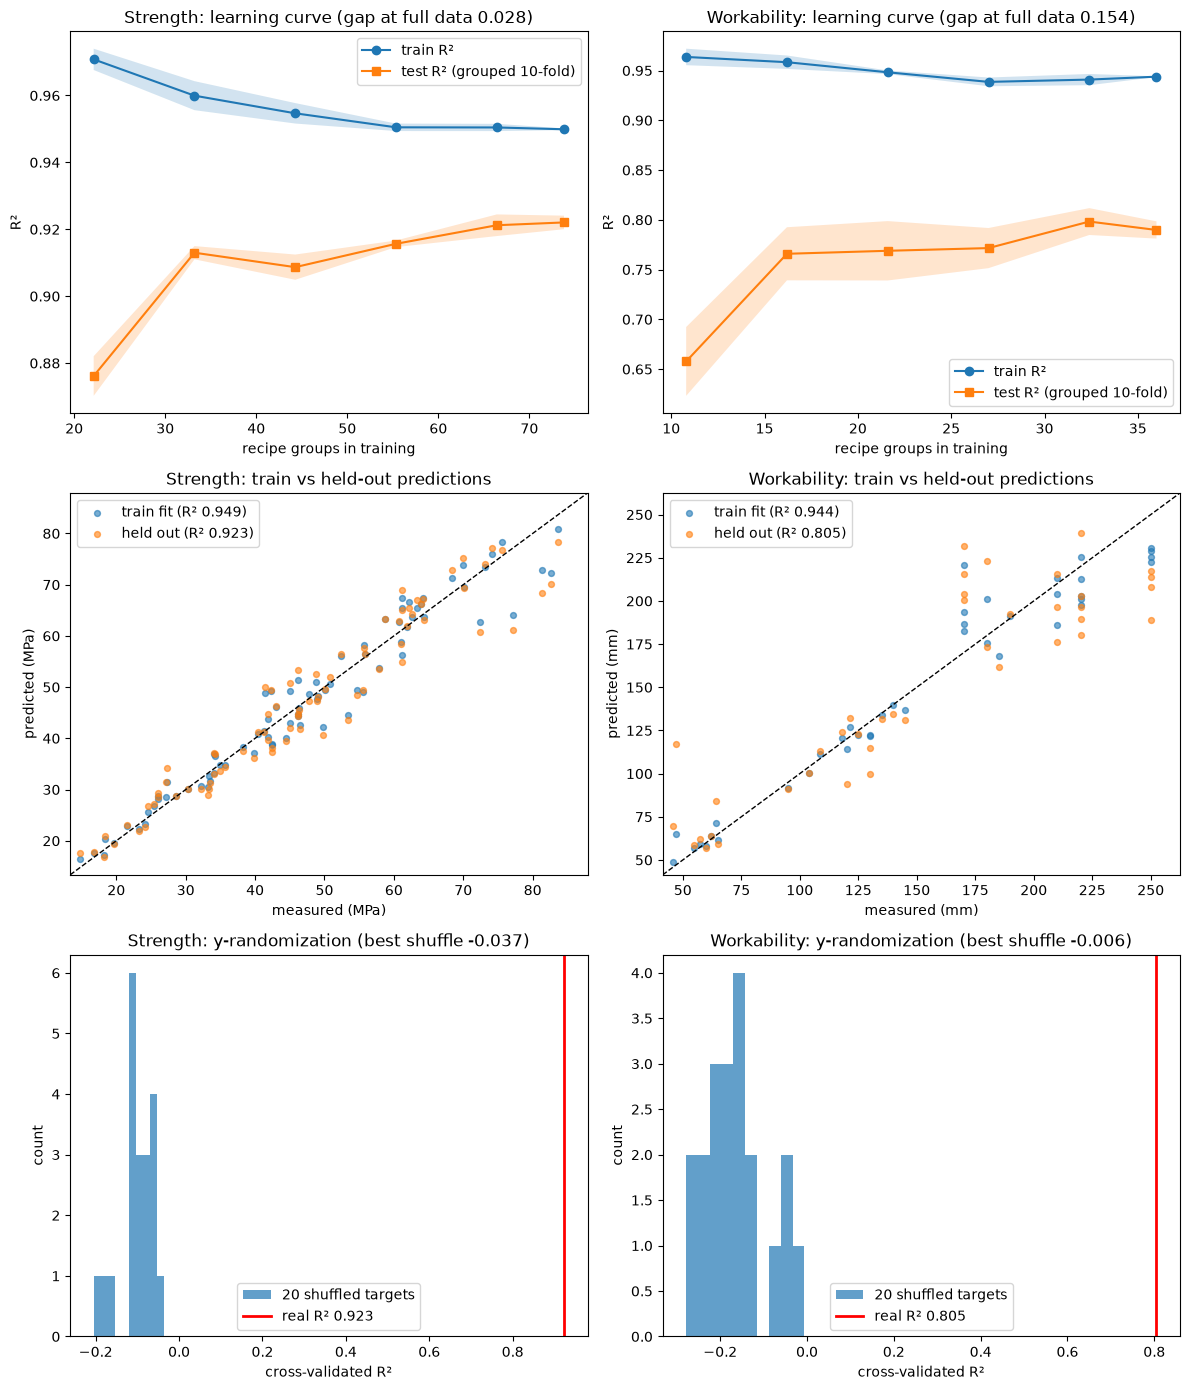

In [36]:
import numpy as np, matplotlib.pyplot as plt

TARGETS = [('Strength', DS, 'fc', 'MPa'), ('Workability', DW, 'slump_mm', 'mm')]

def learning_curve(D, target, fracs=(0.3, 0.45, 0.6, 0.75, 0.9, 1.0), seeds=(0, 1, 2)):
    """Test R2 (grouped 10-fold) and train R2 as the training set grows."""
    ly = D.ly.values; n = len(D); out = []
    for frac in fracs:
        te_s, tr_s = [], []
        for seed in seeds:
            rng = np.random.default_rng(seed); mu = np.zeros(n); tr_r2 = []
            for te in kfold(n, 10, rng):
                tr = np.setdiff1d(np.arange(n), te)
                tr = rng.choice(tr, max(8, int(round(frac * len(tr)))), replace=False)
                mu[te] = fit_predict(D, target, tr, te, restarts=0)[0]
                tr_r2.append(r2(ly[tr], fit_predict(D, target, tr, tr, restarts=0)[0]))
            te_s.append(r2(ly, mu)); tr_s.append(np.mean(tr_r2))
        out.append((frac * 0.9 * n, np.mean(te_s), np.std(te_s), np.mean(tr_s), np.std(tr_s)))
    return np.array(out)

def y_randomization(D, target, n_perm=20):
    ly = D.ly.values; n = len(D); rng = np.random.default_rng(1000); scores = []
    for i in range(n_perm):
        perm = rng.permutation(ly); mu = np.zeros(n)
        for te in kfold(n, 10, np.random.default_rng(i)):
            tr = np.setdiff1d(np.arange(n), te); mu[te] = fit_predict(D, target, tr, te, ly=perm, restarts=0)[0]
        scores.append(r2(perm, mu))
    return np.array(scores)

curves = {t: learning_curve(D, t) for _, D, t, _ in TARGETS}
yrand  = {t: y_randomization(D, t) for _, D, t, _ in TARGETS}

fig, ax = plt.subplots(3, 2, figsize=(12, 14))
for col, (name, D, target, unit) in enumerate(TARGETS):
    ly = D.ly.values; y = np.exp(ly); mu_cv = RESULTS[target]['mu']
    mu_in = fit_predict(D, target, np.arange(len(D)), np.arange(len(D)))[0]
    lc = curves[target]

    # (1) learning curve: a closing gap means the model generalises
    a = ax[0, col]
    a.plot(lc[:, 0], lc[:, 3], 'o-', label='train R²')
    a.fill_between(lc[:, 0], lc[:, 3] - lc[:, 4], lc[:, 3] + lc[:, 4], alpha=0.2)
    a.plot(lc[:, 0], lc[:, 1], 's-', label='test R² (grouped 10-fold)')
    a.fill_between(lc[:, 0], lc[:, 1] - lc[:, 2], lc[:, 1] + lc[:, 2], alpha=0.2)
    a.set_xlabel('recipe groups in training'); a.set_ylabel('R²')
    a.set_title(f'{name}: learning curve (gap at full data {lc[-1, 3] - lc[-1, 1]:.3f})'); a.legend()

    # (2) train vs test parity: points far apart = overfitting
    a = ax[1, col]; lim = [y.min() * 0.9, y.max() * 1.05]
    a.scatter(y, np.exp(mu_in), s=18, alpha=0.6, label=f'train fit (R² {r2(ly, mu_in):.3f})')
    a.scatter(y, np.exp(mu_cv), s=18, alpha=0.6, label=f'held out (R² {r2(ly, mu_cv):.3f})')
    a.plot(lim, lim, 'k--', lw=1); a.set_xlim(lim); a.set_ylim(lim)
    a.set_xlabel(f'measured ({unit})'); a.set_ylabel(f'predicted ({unit})')
    a.set_title(f'{name}: train vs held-out predictions'); a.legend()

    # (3) y-randomization: real R2 must sit far to the right of the shuffled scores
    a = ax[2, col]; real = r2(ly, mu_cv)
    a.hist(yrand[target], bins=10, alpha=0.7, label=f'{len(yrand[target])} shuffled targets')
    a.axvline(real, color='red', lw=2, label=f'real R² {real:.3f}')
    a.set_xlabel('cross-validated R²'); a.set_ylabel('count')
    a.set_title(f'{name}: y-randomization (best shuffle {yrand[target].max():.3f})'); a.legend()

plt.tight_layout(); plt.savefig('overfitting_checks.png', dpi=150); plt.show()